# FundusVision - Normal vs Abnormal screening (ResNet34)

This notebook walks through the classification pipeline in the `fundusvision` package:
per-eye labels from ODIR-5K, a **patient-grouped** split, ImageNet-pretrained ResNet34 fine-tuning,
validation-selected decision thresholds and Grad-CAM explanations.

Everything heavy lives in the package (`src/fundusvision`), so the cells below are short and
reproducible from the command line too:

```bash
fundusvision download odir            # ~1.9 GB from Kaggle (needs ~/.kaggle/kaggle.json)
fundusvision train-classifier         # writes results/classifier/{best_model.pt,history.json,split.csv}
fundusvision eval-classifier          # writes results/classifier/metrics.json + docs/figures/*.png
fundusvision explain                  # Grad-CAM grid
```

In [1]:
import os
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
os.chdir(ROOT)  # run-relative paths (results/, data/) resolve from the repo root
FIGURES = ROOT / "docs" / "figures"
pd.set_option("display.precision", 4)

DATA_DIR = ROOT / "data" / "odir5k"
RUN_DIR = ROOT / "results" / "classifier"

## 1. Labels and split

Each ODIR-5K row carries *both* eyes of a patient. We melt that into one row per physical image,
label each eye from **its own** diagnostic keywords, and split by patient so no eye of a test
patient is ever seen in training. `patient_grouped_split` raises if any image or patient leaks.

In [2]:
from fundusvision.data import build_eye_table, patient_grouped_split

eyes = build_eye_table(DATA_DIR / "full_df.csv", DATA_DIR / "preprocessed_images")
split = patient_grouped_split(eyes, seed=42)
print(split.summary())
eyes.sample(5, random_state=0)[["patient_id", "side", "keywords", "label"]]

train:  4566 images |  2398 patients |  55.0% abnormal
val  :   913 images |   480 patients |  55.1% abnormal
test :   913 images |   480 patients |  55.1% abnormal


,patient_id,side,keywords,label
2026,3044,left,normal fundus,0
3000,4638,left,mild nonproliferative retinopathy,1
3431,270,right,wet age-related macular degeneration,1
5081,2737,right,normal fundus,0
5023,2670,right,normal fundus,0


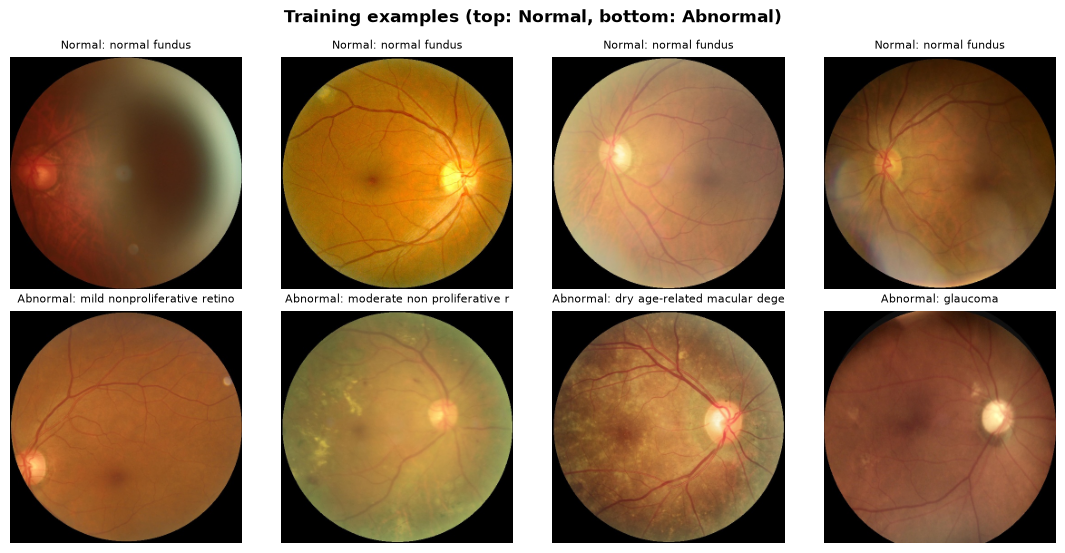

In [3]:
import matplotlib.pyplot as plt

from fundusvision.data.odir import CLASS_NAMES, load_rgb

sample = pd.concat([split.train[split.train.label == c].sample(4, random_state=1) for c in (0, 1)])
fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
for ax, (_, row) in zip(axes.flat, sample.iterrows(), strict=True):
    ax.imshow(load_rgb(row.path, 256))
    ax.set_title(f"{CLASS_NAMES[row.label]}: {row.keywords[:28]}", fontsize=8)
    ax.axis("off")
fig.suptitle("Training examples (top: Normal, bottom: Abnormal)", fontweight="bold")
plt.tight_layout()

## 2. Training

Training takes ~15-30 min on an Apple-silicon GPU or a Colab T4. The checkpoint, history and the
exact split used are saved under `results/classifier/`. Flip `RUN_TRAINING` to retrain here.

In [4]:
RUN_TRAINING = False

if RUN_TRAINING:
    from fundusvision.training import ClassifierConfig, train_classifier

    train_classifier(ClassifierConfig(data_dir=DATA_DIR, output_dir=RUN_DIR))
else:
    print(f"Using the saved run in {RUN_DIR.relative_to(ROOT)}")

history = pd.DataFrame(pd.read_json(RUN_DIR / "history.json"))
history[["epoch", "train_loss", "val_loss", "val_acc", "val_f1", "val_auc", "best"]].tail(8)

Using the saved run in results/classifier


,epoch,train_loss,val_loss,val_acc,val_f1,val_auc,best
17,18,0.4184,0.5257,0.7043,0.7013,0.7809,False
18,19,0.4059,0.5133,0.7152,0.7210,0.7931,False
19,20,0.3988,0.5308,0.6933,0.6854,0.7871,False
20,21,0.3707,0.5271,0.6944,0.6869,0.7814,False
21,22,0.3565,0.5370,0.6878,0.6932,0.7698,False
22,23,0.3422,0.5865,0.6769,0.6558,0.7804,False
23,24,0.3237,0.5305,0.7065,0.7124,0.7828,False
24,25,0.3081,0.5527,0.6911,0.6968,0.7854,False


## 3. Evaluation

Decision thresholds are chosen on the **validation** split (max F1 and max Youden's J) and then
applied unchanged to the held-out test split. ROC / PR AUC are threshold-free.

In [5]:
from fundusvision.evaluation import evaluate_classifier

report = evaluate_classifier(RUN_DIR, figures_dir=FIGURES)
rows = {f"test @ {name} ({thr:.2f})": report["test"][name]
        for name, thr in report["thresholds"].items()}
cols = ["accuracy", "balanced_accuracy", "recall", "specificity", "precision", "npv", "f1",
        "mcc", "kappa", "roc_auc", "pr_auc"]
pd.DataFrame(rows).T[cols]

test @ val-Youden threshold 0.449: acc 0.747 | sens 0.712 | spec 0.790 | F1 0.756 | ROC AUC 0.817 | PR AUC 0.875


,accuracy,balanced_accuracy,recall,specificity,precision,npv,f1,mcc,kappa,roc_auc,pr_auc
test @ default (0.50),0.7481,0.7569,0.6700,0.8439,0.8404,0.6758,0.7456,0.5150,0.5023,0.8175,0.8749
test @ val_f1 (0.26),0.6944,0.6751,0.8648,0.4854,0.6734,0.7453,0.7572,0.3829,0.3618,0.8175,0.8749
test @ val_youden (0.45),0.7470,0.7510,0.7117,0.7902,0.8063,0.6908,0.7561,0.4995,0.4954,0.8175,0.8749


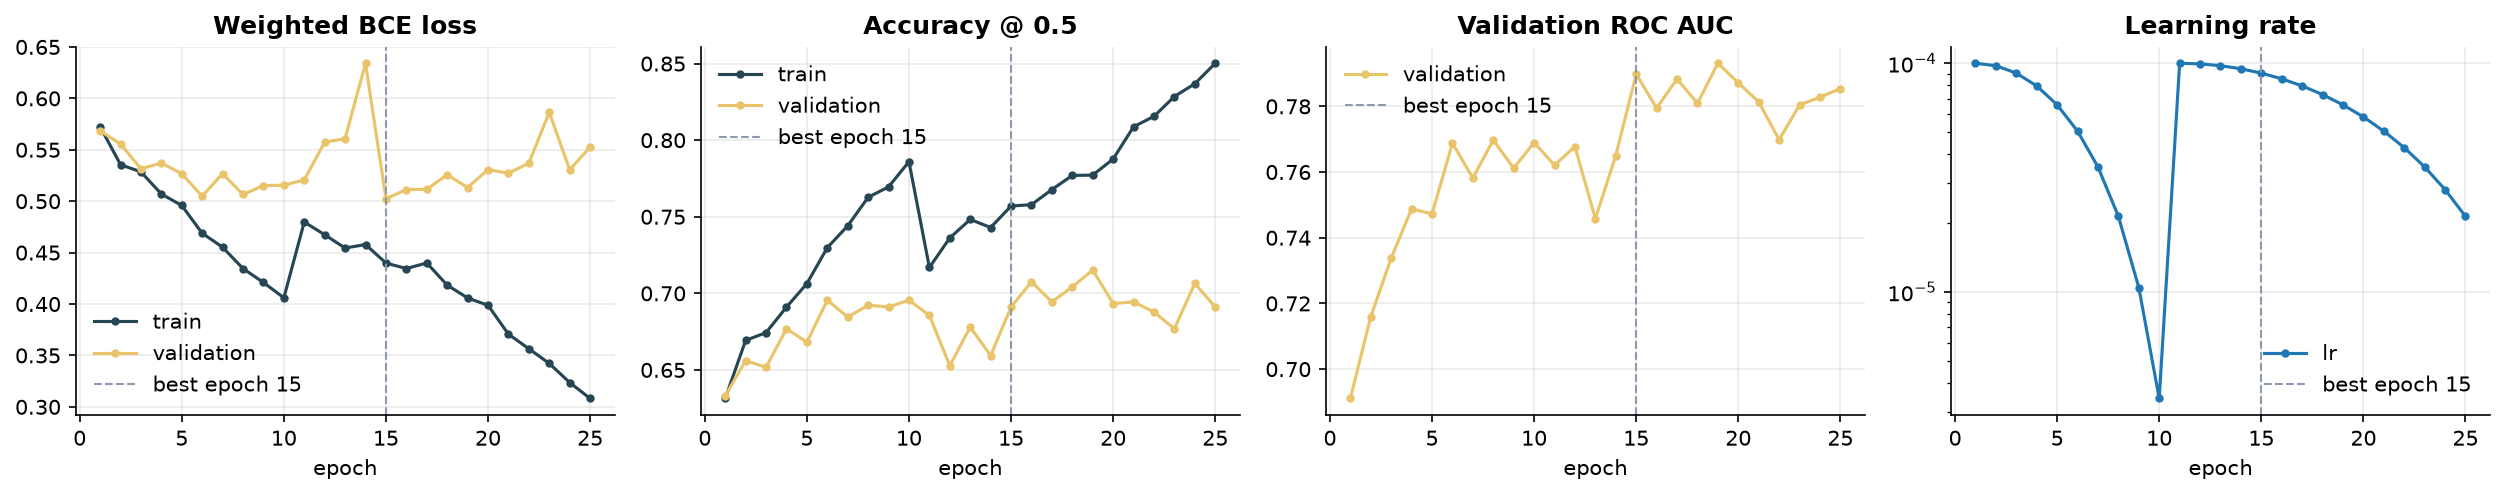

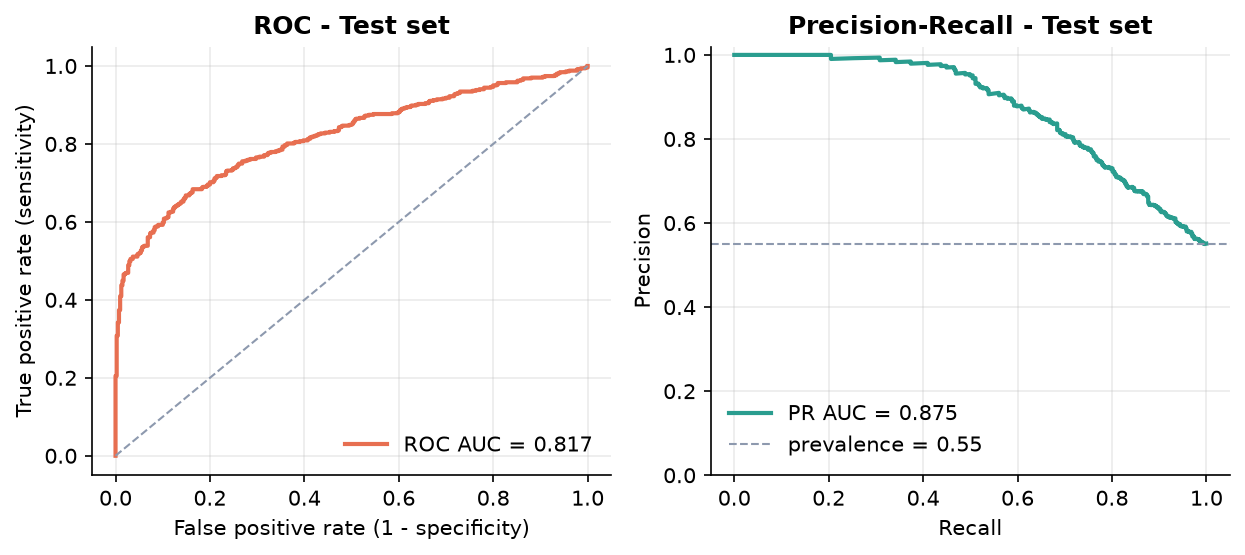

In [6]:
display(Image(filename=FIGURES / "classifier_training_curves.png"))
display(Image(filename=FIGURES / "classifier_roc_pr.png"))

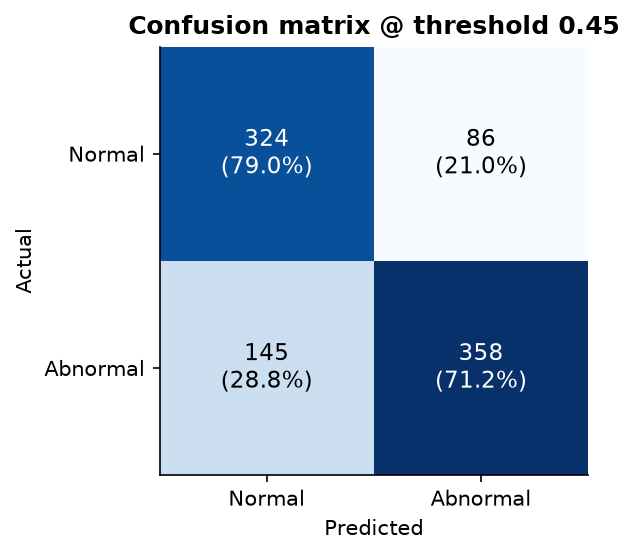

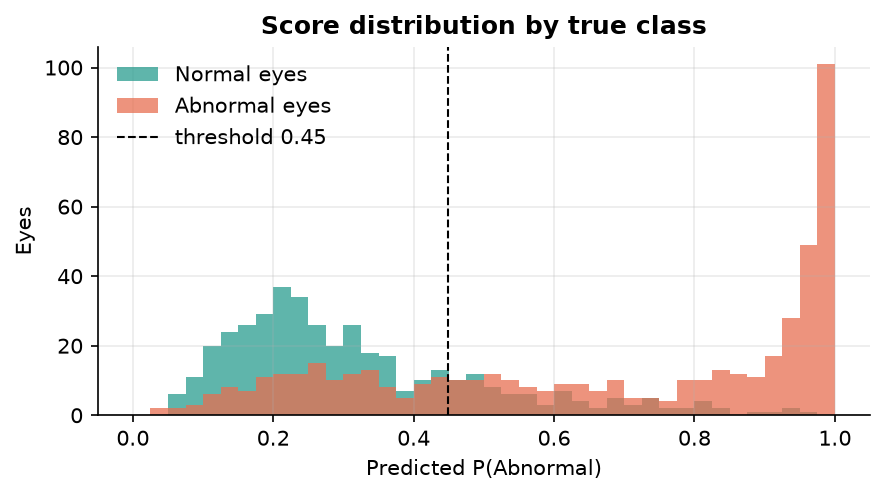

In [7]:
display(Image(filename=FIGURES / "classifier_confusion_matrix.png"))
display(Image(filename=FIGURES / "classifier_score_distribution.png"))

## 4. Error analysis and Grad-CAM

The most confident mistakes on the test split, then Grad-CAM heat-maps over `layer4` for a few
correctly handled eyes of each class.

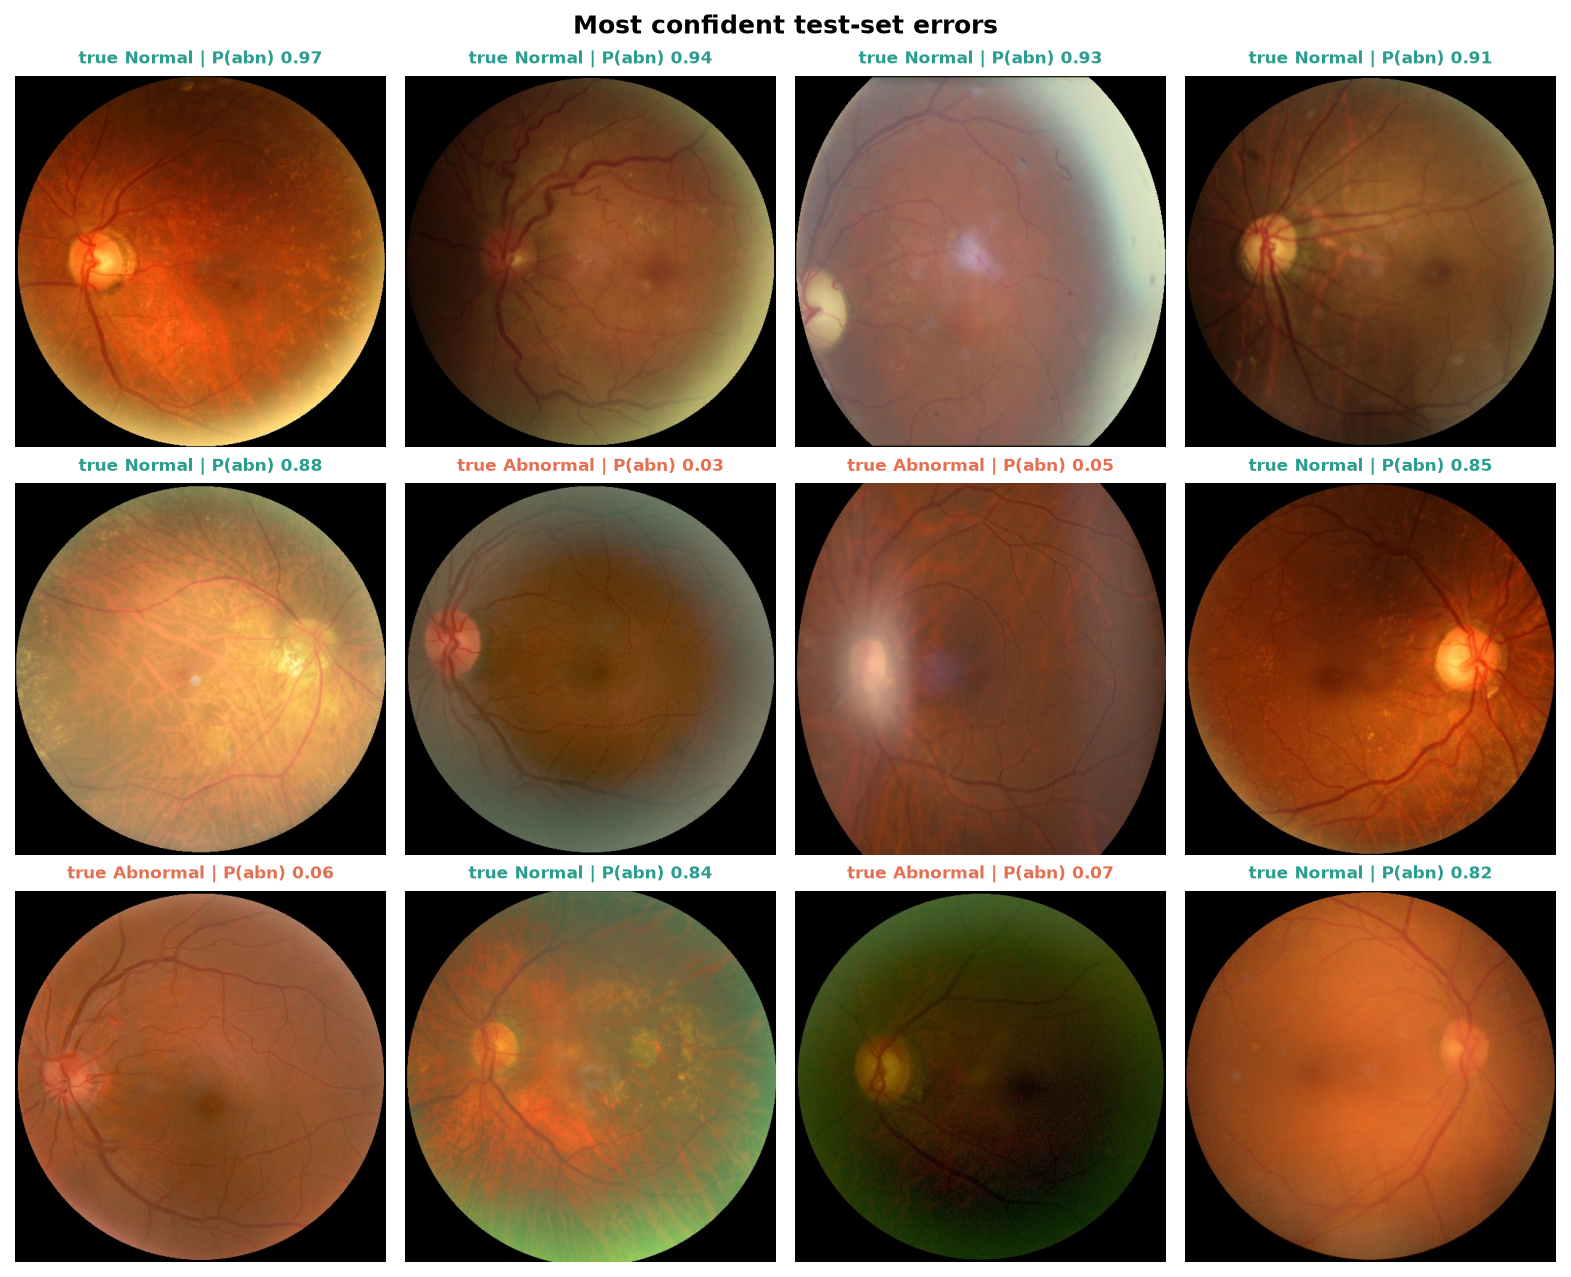

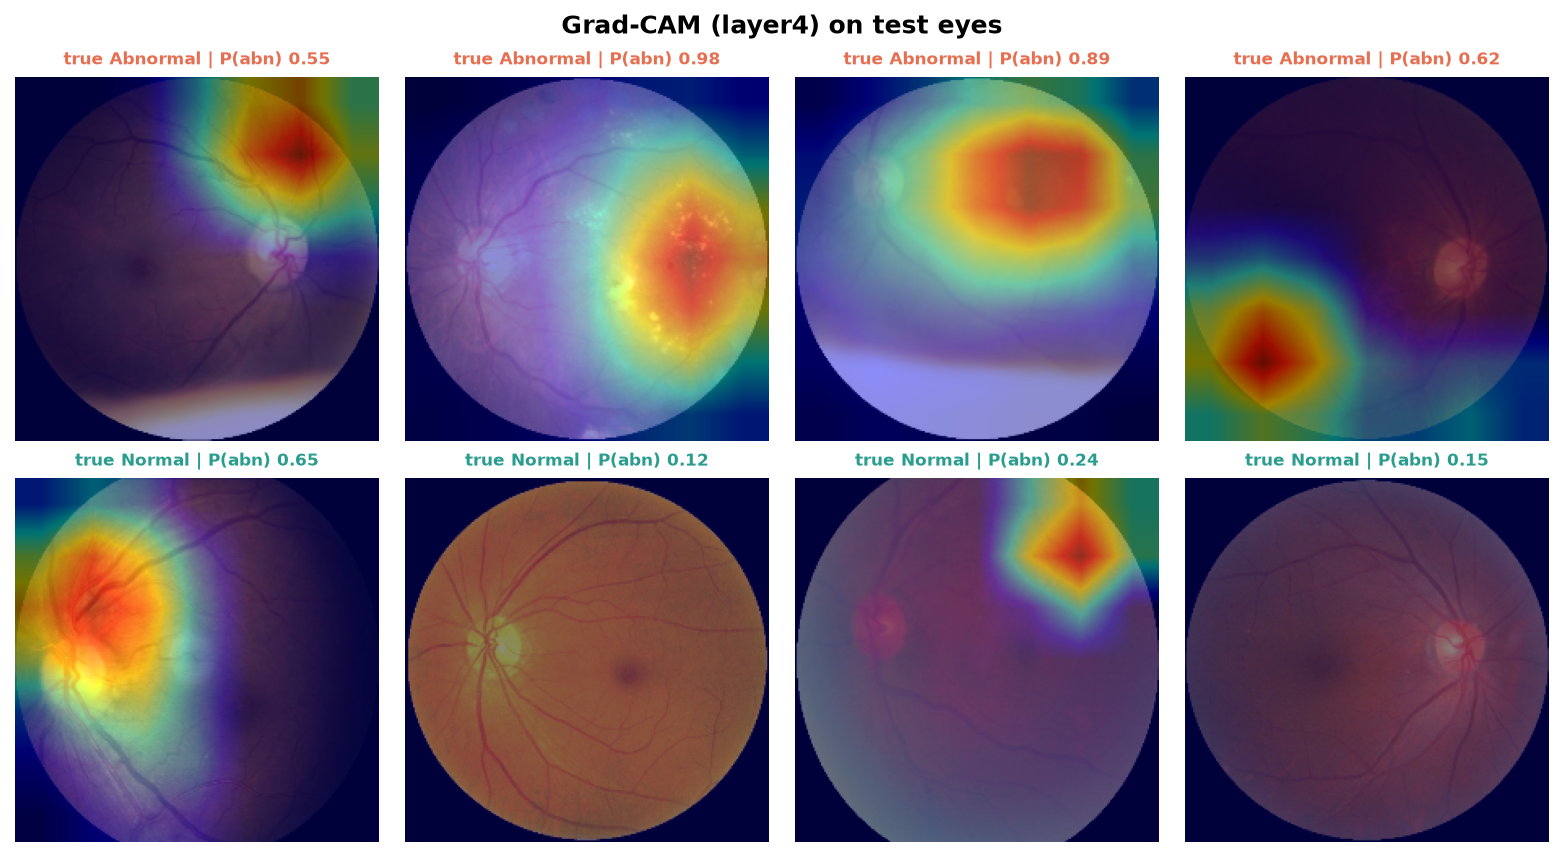

In [8]:
from fundusvision.explain import make_gradcam_figure

display(Image(filename=FIGURES / "classifier_misclassified.png"))
display(Image(filename=make_gradcam_figure(RUN_DIR, FIGURES / "classifier_gradcam.png")))

## Notes

* **Why these numbers are lower than the project's first report.** The original pipeline duplicated
  every image ~1.95x and split at the row level, so ~half of the "test" images were also in training.
  The numbers above come from a leak-free, patient-grouped split and are the honest ones.
* Normal/Abnormal is a *screening* framing: an Abnormal eye may carry any of diabetes, glaucoma,
  cataract, AMD, hypertension, myopia or "other" findings. The score distribution shows the overlap
  that remains between classes at 224 px.
* Next steps worth trying: higher input resolution, multi-label heads per disease, test-time
  augmentation, and external validation on a second fundus dataset.